# 09 · Emotion Mirror: Model Serving and API Validation

This notebook documents the model-serving component of **Emotion Mirror**, an application for comparing emotion classifiers on short English texts. The local classifiers evaluated in notebooks 02–06 and the selected DeepSeek few-shot configuration from notebook 07 are exposed through a common HTTP interface. The objective is to preserve their preprocessing, label definitions and calibrated predictions while supporting interactive comparison and explicit handling of invalid requests.

The notebook presents the rationale for the deployed model set, the inference architecture, example responses and reproducible verification of the service. It evaluates software correctness rather than introducing a new modelling experiment. The API constitutes the backend component; graphical interaction, speech transcription, facial analysis and public deployment are outside the validation reported here.

**Data-use statement.** Model parameters and calibration temperatures were fixed in the earlier experiments using their original training and validation splits. Test-set results below are read from the existing evaluation ledger and are not used to refit or tune the service. Hand-written demonstration inputs have no assigned gold labels and do not constitute an additional accuracy evaluation.

## 1. Reproducible execution

The analysis uses Python 3.11 and the project environment specified in `requirements.txt`, `requirements-models.txt` and `requirements-test.txt`. All five local classifiers are loaded from saved artifacts and run on CPU. No training or dataset download is required. Section 4.1 additionally documents an opt-in paid DeepSeek request. It requires network access and a server-side API key. Ordinary notebook reruns skip this request unless `EMOTION_RUN_LIVE_LLM=1` is set before starting the kernel; the submitted outputs record the observed live validation.

The recorded package versions identify the environment in which the displayed outputs were produced. Project paths are resolved relative to the repository so that the notebook can be executed from either the repository root or its `notebooks/` directory.

In [1]:
import os
import sys
import json
import hashlib
import logging
import subprocess
import tempfile
import xml.etree.ElementTree as ET
from pathlib import Path
from importlib.metadata import version

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
assert (ROOT / "src/config.py").is_file(), "Run from the project root or notebooks/."
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Hide download/loading progress widgets, not inference or validation errors.
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").addFilter(
    lambda record: "Redirects are currently not supported" not in record.getMessage()
)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from fastapi.testclient import TestClient
from transformers.utils import logging as transformers_logging

from api.main import create_app
from api.model_service import ModelService
from api.schemas import MODEL_IDS
from src.config import LABELS, EMOTION_COLORS

transformers_logging.disable_progress_bar()
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 90)

packages = ["numpy", "scikit-learn", "torch", "transformers", "fastapi", "pydantic", "openai", "python-dotenv"]
environment = pd.DataFrame({"Package": ["Python"] + packages,
                            "Version": [sys.version.split()[0]] + [version(p) for p in packages]})
display(environment.style.hide(axis="index"))

Package,Version
Python,3.11.9
numpy,2.4.6
scikit-learn,1.9.1
torch,2.15.0
transformers,5.22.2
fastapi,0.162.5
pydantic,2.14.3
openai,3.49.0
python-dotenv,1.2.4


### 1.1 Artifact integrity

The pre-service snapshot records SHA-256 digests of the trained artifacts and supporting files. The following check compares the current serving artifacts against that manifest, including the three classical pipelines, the BiLSTM checkpoint, BERT weights and tokenizer files, and the saved calibration temperatures. A mismatch raises an error rather than being silently accepted. This establishes byte-level continuity with the archived experiments; it does not independently establish the statistical validity of those experiments.

In [2]:
manifest = json.loads((ROOT / "docs/reproducibility/baseline_manifest.json").read_text())
recorded = {item["path"]: item for item in manifest["files"]}
artifact_groups = {
    "Classical pipelines": [f"models/classical/{m}.joblib" for m in ("bow_nb", "tfidf_lr", "improved_lr")],
    "BiLSTM checkpoint": ["models/bilstm/bilstm.pt"],
    "BERT weights and configuration": ["models/bert/model.safetensors", "models/bert/config.json", "models/bert/training_info.json"],
    "BERT tokenizer": [f"models/bert/{f}" for f in ("tokenizer.json", "tokenizer_config.json", "vocab.txt")],
    "Validation temperatures": [f"results/metrics/temperature_{name}.json" for name in ("improved_classical", "bilstm", "bert")],
}

def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

integrity = []
for group, paths in artifact_groups.items():
    verified = all(sha256(ROOT / path) == recorded[path]["sha256"] for path in paths)
    integrity.append({"Artifact group": group, "Files": len(paths), "Matches archived artifacts": verified})
    assert verified, f"Artifact mismatch: {group}"
display(pd.DataFrame(integrity).style.hide(axis="index"))

Artifact group,Files,Matches archived artifacts
Classical pipelines,3,True
BiLSTM checkpoint,1,True
BERT weights and configuration,3,True
BERT tokenizer,3,True
Validation temperatures,3,True


## 2. Model selection for interactive comparison

Six previously evaluated configurations are exposed by the service: five local classifiers and the selected remote DeepSeek few-shot configuration. This set covers contrasting representations and modelling choices. It is a selection of configurations for demonstration, not a new optimisation of model hyperparameters.

| Model | Role in the comparison |
|---|---|
| BoW + Naive Bayes | A generative count-based baseline that provides a reference for the stronger classifiers. |
| TF-IDF + logistic regression | A sparse, discriminative baseline and the default comparator. |
| Improved logistic regression | The selected classical configuration using sublinear term frequency and class weighting. |
| BiLSTM | A sequential encoder using fine-tuned GloVe embeddings, representing the contribution of word order. |
| Fine-tuned BERT | A contextual encoder; its configuration was selected by validation macro-F1 in notebook 06. |
| DeepSeek few-shot (`llm`) | The `deepseek-flash` model and `fs_random_k3` prompt selected in notebook 07, with 18 training demonstrations. |

TF-IDF + LR and BERT form the default pair. BiLSTM is also retained because notebook 08 found no statistically significant accuracy difference between it and BERT (McNemar *p* ≈ 0.85). The numerical difference in test macro-F1 should therefore not be described as established superiority of BERT.

BoW + LR and averaged GloVe remain in the offline evaluation. BoW + LR overlaps the sparse discriminative comparison, while averaged GloVe requires a separate vector cache and offers less benefit for the live demonstration given its earlier results. The BiLSTM checkpoint already contains its embedding weights. DeepSeek is called only when the request explicitly includes `llm`. It uses the saved prompt and decoding settings, with credentials loaded on the server. Its scores apply to the shared 300-text subset, not the complete test set used in Table 1. The common-subset comparison below keeps these evaluation populations separate.

**Table 1. Previously obtained validation and test results for the served configurations.** The complete test set contains 2,000 texts. These values are imported from the existing ledger rather than recomputed or used for selection here.

In [3]:
service = ModelService(model_ids=MODEL_IDS, device="cpu")
registry = service.registry()
selection = pd.DataFrame([
    {"Model": model["id"], "Role": model["role"],
     "Validation macro-F1": model["test_metrics"]["val_macro_f1"],
     "Test accuracy": model["test_metrics"]["accuracy"],
     "Test macro-F1": model["test_metrics"]["macro_f1"]}
    for model in registry["models"] if model["id"] in MODEL_IDS
])
display(selection.style.hide(axis="index").format({
    "Validation macro-F1": "{:.4f}", "Test accuracy": "{:.4f}", "Test macro-F1": "{:.4f}"}))

Model,Role,Validation macro-F1,Test accuracy,Test macro-F1
bow_nb,baseline,0.7187,0.8015,0.6949
tfidf_lr,baseline,0.8650,0.8815,0.8320
improved_lr,improved,0.8778,0.8850,0.8429
bilstm,improved,0.9148,0.9315,0.8939
bert,improved,0.9224,0.9300,0.8962


### 2.1 Comparable evaluation population

**Table 1b. Historical results on the same 300-text test subset.** These are the ledger’s existing results, not new measurements from live requests. Only this common subset supports a direct six-model score comparison. The 2,000-text local-model results in Table 1 must not be ranked against DeepSeek’s subset scores. No model or prompt is reselected using these test results.

In [4]:
subset_table = pd.DataFrame([
    {"Model": m["id"], "Test texts": 300,
     "Subset accuracy": m["subset300_metrics"]["accuracy"],
     "Subset macro-F1": m["subset300_metrics"]["macro_f1"]}
    for m in registry["models"]
])
display(subset_table.style.hide(axis="index").format({
    "Subset accuracy": "{:.4f}", "Subset macro-F1": "{:.4f}"}))

Model,Test texts,Subset accuracy,Subset macro-F1
bow_nb,300,0.8367,0.7313
tfidf_lr,300,0.8933,0.8358
improved_lr,300,0.8900,0.8397
bilstm,300,0.9367,0.8950
bert,300,0.9433,0.9251
llm,300,0.7533,0.7129


## 3. Service architecture and inference contract

The implementation separates HTTP validation (`api/schemas.py`), request routing and application lifecycle (`api/main.py`), and model loading and inference (`api/model_service.py`). The service reuses `src/predictors.py` and the saved local artifacts. `api/deepseek_service.py` reuses `src/llm.py`, `results/llm/selection.json` and `results/llm/prompt_llm.json` for remote inference.

The processing sequence is:

**English text and model IDs → request validation → saved preprocessing and classifier → temperature calibration → labelled JSON response.**

Models are loaded once per application process during startup. Requests reuse those model instances. Local inference calls are serialized to avoid races in the existing neural helpers and simultaneous allocation of multiple inference workloads. Remote requests run outside this local lock, so waiting for DeepSeek does not block another request for local inference. The startup and shutdown logic releases model references when the application context closes.

| Endpoint | Purpose | Response behaviour |
|---|---|---|
| `GET /health` | Report availability of the configured models | HTTP 200 when all configured local models are ready; optional DeepSeek configuration is reported separately. Credentials alone do not establish connectivity or sufficient credit. A remote-only service requires a configured client. |
| `GET /models` | List model IDs, roles, availability and evaluation metadata | Disabled models are distinguished from enabled models that failed to load. |
| `POST /predict` | Apply the selected models to one text | HTTP 200 includes successful predictions and any per-model errors; HTTP 503 when no requested model succeeds. Invalid requests receive HTTP 422. |

The request accepts 1–2,000 characters and a non-empty list of unique supported model IDs. Leading and trailing whitespace is removed; all other preprocessing remains model-specific. The requirement for at least one Latin letter rejects empty or non-text-like input but is **not** a language detector. Unknown fields, duplicate model IDs and unsupported control characters are rejected.

Each local prediction reports the winning label, its probability, all six class probabilities, the calibration temperature, elapsed inference time, device and truncation metadata. DeepSeek reports a label, served model, prompt ID, demonstration count, parsing status and token usage; its confidence, class probabilities and calibration temperature are `null`. No validated six-class distribution is available from this configuration. Decoding temperature 0 is reported separately and must not be interpreted as a calibration temperature. Labels always follow the dataset order: **sadness, joy, love, anger, fear, surprise**. The response also includes errors and an agreement indicator. Agreement is undefined (`null`) when fewer than two models succeed or any requested model fails, preventing missing predictions from being interpreted as agreement.

### 3.1 Calibration

The shared predictor interface returns raw probabilities, including BERT loaded with temperature 1. The service applies the temperature fitted on the validation split in the corresponding modelling notebook:

$$
q_c = \frac{\exp(\log p_c / T)}{\sum_{k=1}^{6}\exp(\log p_k / T)}.
$$

This is equivalent to temperature scaling of logits up to floating-point precision (Guo et al., 2017). It is applied **once**. Positive temperatures preserve the predicted class while changing the sharpness of the distribution. Naive Bayes has no fitted temperature in this project and is returned with $T=1$, explicitly marked uncalibrated. Missing or invalid calibration artifacts make the affected model unavailable rather than silently changing the calculation. Probabilities cannot reconstruct information already lost through numerical underflow.

The maximum class probability describes the classifier's distribution over the six labels. It is neither emotional intensity nor an independently verified measure of a person's psychological state.

## 4. Observed API outputs

FastAPI's `TestClient` executes the application's HTTP routes and lifespan in-process. It exercises the same request handling and model service used by Uvicorn, without starting another network listener. The context manager guarantees cleanup if a check fails. This method verifies application behaviour; it does not measure network latency or public-hosting reliability.

The demonstration inputs are deliberately separated from the original evaluation data:

- **D1:** `i feel excited about our presentation` — an explicit positive expression.
- **D2:** `i feel lonely today` — an explicit sadness-related expression.
- **D3:** `i do not feel happy today` — a negated emotion word, included to expose a limitation discussed in notebook 08.

No reference label is assigned to these examples. In particular, negating happiness does not uniquely imply any one of the remaining five labels.

In [5]:
demo_texts = {
    "D1": "i feel excited about our presentation",
    "D2": "i feel lonely today",
    "D3": "i do not feel happy today",
}
invalid_requests = [
    ("Blank text", {"text": "   "}),
    ("Non-string text", {"text": 42}),
    ("No Latin letters", {"text": "123?!"}),
    ("Unknown model", {"text": "hello", "models": ["unknown"]}),
    ("Duplicate model", {"text": "hello", "models": ["bert", "bert"]}),
    ("Over character limit", {"text": "x" * 2001}),
]

demonstrations, request_checks = {}, []
with TestClient(create_app(service)) as client:
    health_response = client.get("/health")
    assert health_response.status_code == 200, health_response.json()
    assert set(health_response.json()["available_models"]) == set(MODEL_IDS)
    availability = client.get("/models").json()
    for example_id, text in demo_texts.items():
        response = client.post("/predict", json={"text": text, "models": list(MODEL_IDS)})
        assert response.status_code == 200
        result = response.json()
        assert len(result["results"]) == len(MODEL_IDS) and not result["errors"]
        for row in result["results"]:
            assert list(row["probabilities"]) == LABELS
            assert np.isclose(sum(row["probabilities"].values()), 1.0)
        demonstrations[example_id] = result
    for case, payload in invalid_requests:
        observed = client.post("/predict", json=payload).status_code
        request_checks.append({"Condition": case, "Expected HTTP status": 422,
                               "Observed HTTP status": observed, "Passed": observed == 422})
        assert observed == 422
    long_response = client.post("/predict", json={
        "text": "happy " * 180, "models": ["tfidf_lr", "bilstm", "bert"]})
    assert long_response.status_code == 200
    long_result = long_response.json()
    assert not long_result["errors"]
    assert [r["truncated"] for r in long_result["results"]] == [False, True, True]

assert not service.predictors, "Model references should be released after the application context closes."
readiness = pd.DataFrame([
    {"Model": m["id"], "Available at startup": m["available"], "Temperature": m["temperature"]}
    for m in availability["models"] if m["id"] in MODEL_IDS
])
display(readiness.style.hide(axis="index").format({"Temperature": "{:.4f}"}))

Model,Available at startup,Temperature
bow_nb,True,1.0000
tfidf_lr,True,0.8992
improved_lr,True,0.5111
bilstm,True,2.0532
bert,True,1.3199


**Table 2. Predicted labels for three hand-written demonstration inputs.** These observations illustrate operation of the interface; they are not estimates of accuracy or generalisation.

In [6]:
label_table = pd.DataFrame({
    example_id: {row["model_id"]: row["label"] for row in result["results"]}
    for example_id, result in demonstrations.items()
}).reindex(MODEL_IDS)
label_table.index.name = "Model"
display(label_table)

,D1,D2,D3
Model,,,
bow_nb,joy,sadness,joy
tfidf_lr,joy,sadness,joy
improved_lr,joy,sadness,joy
bilstm,joy,sadness,joy
bert,joy,sadness,joy


**Table 3. Classifier confidence and calibration for D1.** Confidence is the probability of the winning label. Inference timings are intentionally omitted from the comparison table because one request, especially the first neural call after loading, is not a controlled latency benchmark.

In [7]:
rows = demonstrations["D1"]["results"]
confidence_table = pd.DataFrame([
    {"Model": r["model_id"], "Prediction": r["label"], "Confidence": r["confidence"],
     "Temperature": r["temperature"], "Calibrated": r["calibrated"]}
    for r in rows
])
display(confidence_table.style.hide(axis="index").format({"Confidence": "{:.4f}", "Temperature": "{:.4f}"}))

Model,Prediction,Confidence,Temperature,Calibrated
bow_nb,joy,0.7283,1.0000,False
tfidf_lr,joy,0.9957,0.8992,True
improved_lr,joy,0.9899,0.5111,True
bilstm,joy,0.9973,2.0532,True
bert,joy,0.9924,1.3199,True


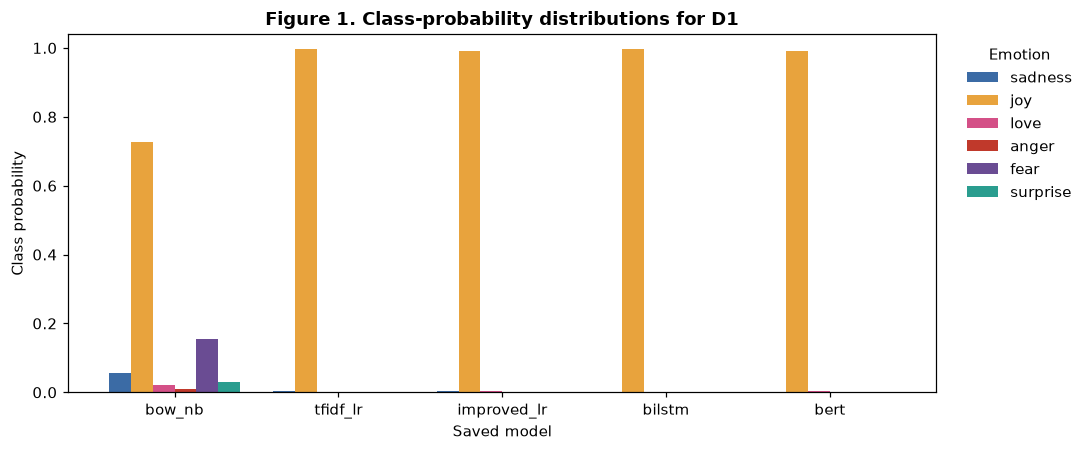

In [8]:
probabilities = pd.DataFrame([row["probabilities"] for row in rows],
                             index=[row["model_id"] for row in rows])[LABELS]
ax = probabilities.plot.bar(figsize=(10, 4.2), width=.8,
                            color=[EMOTION_COLORS[label] for label in LABELS])
ax.set(title="Figure 1. Class-probability distributions for D1", ylabel="Class probability",
       xlabel="Saved model", ylim=(0, 1.04))
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Emotion", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

**Interpretation.** All five models predict *joy* for D1 and *sadness* for D2. For D1, Naive Bayes assigns approximately 0.728 to *joy*, whereas the other models assign probabilities above 0.98 after their saved calibration transformations. Agreement on a label therefore coexists with different probability distributions; this single example does not establish which distribution is better calibrated.

All five models also predict *joy* for D3, despite the explicit negation of *happy*. This observation is consistent with the negation failures documented in notebook 08 and illustrates why a successful API response should not be confused with a semantically adequate interpretation. The sentence has no gold label in this demonstration, and the six-label inventory does not contain *neutral*; the result is consequently discussed as a linguistic limitation rather than scored as a new test-set error. Neither calibration nor API packaging corrects the underlying modelling limitation.

### 4.1 Live DeepSeek comparison

The remote adapter preserves the selected `deepseek-flash` model, `fs_random_k3` prompt (18 demonstrations), decoding temperature 0, 32-token output budget, JSON mode and disabled thinking. It reuses the original label parser and at most one corrective follow-up. Token log-probability collection is disabled because this serving configuration has no validated class-probability estimate. SDK retries are disabled and the per-operation network timeout is 15 seconds. This is not an end-to-end latency guarantee.

The opt-in check below compares D3 with TF-IDF + LR, BERT and DeepSeek through the same HTTP route. It sends the demonstration text and saved few-shot prompt to DeepSeek and incurs provider charges. The key remains server-side; the serving adapter does not write visitor text to the experimental JSONL cache. The saved validation record contains only this explicitly documented demonstration, never credentials.

**Table 3b. Observed local–remote comparison for D3.** Missing DeepSeek confidence is displayed as N/A, not zero or an artificial one-hot distribution. An observed disagreement illustrates different responses to this input; one example cannot establish model superiority. The provider-reported token counts document this transaction’s usage without estimating cost from potentially outdated prices.

In [9]:
RUN_LIVE_DEEPSEEK = os.environ.get("EMOTION_RUN_LIVE_LLM") == "1"
if RUN_LIVE_DEEPSEEK:
    from datetime import datetime, timezone
    live_service = ModelService(model_ids=("tfidf_lr", "bert", "llm"), device="cpu")
    with TestClient(create_app(live_service)) as live_client:
        live_response = live_client.post("/predict", json={
            "text": demo_texts["D3"], "models": ["tfidf_lr", "bert", "llm"]})
        live_result = live_response.json()
        assert live_response.status_code == 200 and not live_result["errors"], live_result["errors"]
        assert len(live_result["results"]) == 3
        remote_result = next(r for r in live_result["results"] if r["model_id"] == "llm")
        assert remote_result["probabilities"] is None and remote_result["confidence"] is None
        assert remote_result["prompt_id"] == "fs_random_k3" and remote_result["n_shots"] == 18
        live_openapi = live_client.get("/openapi.json").json()
    display(pd.DataFrame([
        {"Model": r["model_id"], "Prediction": r["label"], "Provider": r["provider"],
         "Confidence": "N/A" if r["confidence"] is None else f'{r["confidence"]:.4f}'}
        for r in live_result["results"]
    ]).style.hide(axis="index"))
    display(pd.DataFrame([{
        "Served model": remote_result["served_model"], "Prompt": remote_result["prompt_id"],
        "Demonstrations": remote_result["n_shots"], "Parsing": remote_result["parsing_status"],
        **remote_result["usage"]
    }]).style.hide(axis="index"))
    evidence = {"observed_at_utc": datetime.now(timezone.utc).isoformat(),
                "method": "In-process HTTP route with real local inference and real DeepSeek network request",
                "response": live_result}
    (ROOT / "docs/reproducibility/deepseek_live_validation.json").write_text(json.dumps(evidence, indent=2) + "\n")
    (ROOT / "docs/api_openapi.json").write_text(json.dumps(live_openapi, indent=2) + "\n")
    (ROOT / "docs/api_example_response.json").write_text(json.dumps(live_result, indent=2) + "\n")
else:
    print("Live DeepSeek validation skipped. Set EMOTION_RUN_LIVE_LLM=1 before starting the kernel to opt in.")

Live DeepSeek validation skipped. Set EMOTION_RUN_LIVE_LLM=1 before starting the kernel to opt in.


## 5. Input handling and verification

### 5.1 Invalid requests and long inputs

**Table 4. Observed responses to invalid requests.** Every condition below is tested against the application, and an unexpected status interrupts notebook execution.

In [10]:
display(pd.DataFrame(request_checks).style.hide(axis="index"))

Condition,Expected HTTP status,Observed HTTP status,Passed
Blank text,422,422,True
Non-string text,422,422,True
No Latin letters,422,422,True
Unknown model,422,422,True
Duplicate model,422,422,True
Over character limit,422,422,True


**Table 5. Model-specific handling of a 180-word input.** BiLSTM uses its original 66-word-token limit. BERT uses 128 WordPiece tokens, including special tokens. Classical pipelines process the entire accepted input, so their token count and limit fields are not applicable.

In [11]:
length_table = pd.DataFrame([
    {"Model": r["model_id"],
     "Input tokens": str(r["input_tokens"]) if r["input_tokens"] is not None else "Not applicable",
     "Token limit": str(r["token_limit"]) if r["token_limit"] is not None else "No model-specific truncation",
     "Truncated": r["truncated"], "Warning returned": bool(r["warnings"])}
    for r in long_result["results"]
])
display(length_table.style.hide(axis="index"))

Model,Input tokens,Token limit,Truncated,Warning returned
tfidf_lr,Not applicable,No model-specific truncation,False,False
bilstm,180,66,True,True
bert,182,128,True,True


The explicit truncation fields make a comparison limitation visible: for a sufficiently long accepted text, the classifiers do not all receive the same span. Request-level acceptance therefore does not guarantee model-level equivalence of input coverage.

### 5.2 Automated test suite

The suite in `tests/test_api.py` combines controlled contract checks with an integration check using the actual saved models. `tests/test_deepseek_api.py` additionally checks the selected prompt, nullable probabilities, missing credentials, timeouts, invalid provider output and partial failures using offline test doubles. Pytest makes no paid requests; the live check in §4.1 is separate. Controlled checks use a small injected predictor so that failure behaviour and a known temperature transformation can be assessed independently of model quality. The integration check loads all five saved models, compares API outputs with independent direct model calls, verifies truncation, checks repeated loading and sends three concurrent requests.

The integration inputs are `i feel happy today`, `i feel lonely today` and `i do not feel happy today`. Probabilities are checked against direct predictions after the same saved-temperature transformation using an absolute tolerance of $2\times10^{-6}$ and NumPy's default relative tolerance. Labels must match the unscaled argmax. These checks test preservation of inference behaviour, not correctness against gold emotion labels.

The following cell executes the suite rather than displaying a manually entered pass count. A temporary JUnit report is used to summarise the observed outcomes; any failure or skipped case causes an assertion failure.

In [12]:
test_environment = os.environ.copy()
test_environment.update({"EMOTION_RUN_MODEL_TESTS": "1", "HF_HUB_OFFLINE": "1",
                         "PYTHONDONTWRITEBYTECODE": "1"})
# Ensure the test run uses the documented default model/origin configuration.
for key in ("EMOTION_API_MODELS", "EMOTION_API_DEVICE", "EMOTION_API_ORIGINS"):
    test_environment.pop(key, None)
with tempfile.TemporaryDirectory(prefix="emotion-api-validation-") as directory:
    report_path = Path(directory) / "results.xml"
    run = subprocess.run(
        [sys.executable, "-m", "pytest", "tests", "-q", "-p", "no:cacheprovider",
         f"--junitxml={report_path}"],
        cwd=ROOT, env=test_environment, capture_output=True, text=True, timeout=180,
    )
    assert run.returncode == 0, run.stdout + run.stderr
    cases = ET.parse(report_path).getroot().findall(".//testcase")
    test_rows = []
    for case in cases:
        name = case.attrib["name"]
        family = ("DeepSeek adapter and failure handling" if "test_deepseek_api" in case.attrib.get("classname", "") else
                  "Real saved-model integration" if name == "test_real_saved_models" else
                  "Input validation" if name.startswith("test_invalid_input") else
                  "Probability safeguards" if name.startswith("test_invalid_probabilities") else
                  "Partial failure and calibration" if name == "test_partial_result_and_health" else
                  "CORS and API schema")
        status = "Failed" if case.find("failure") is not None or case.find("error") is not None else (
            "Skipped" if case.find("skipped") is not None else "Passed")
        test_rows.append({"Check group": family, "Outcome": status})

assert cases and all(row["Outcome"] == "Passed" for row in test_rows)
test_summary = pd.DataFrame(test_rows).groupby(["Check group", "Outcome"], sort=False).size().reset_index(name="Cases")
display(test_summary.style.hide(axis="index"))
print(f"Observed result: {len(test_rows)} passed; 0 failed; 0 skipped.")

Check group,Outcome,Cases
Input validation,Passed,11
Partial failure and calibration,Passed,1
CORS and API schema,Passed,1
Probability safeguards,Passed,3
Real saved-model integration,Passed,1
DeepSeek adapter and failure handling,Passed,7


Observed result: 24 passed; 0 failed; 0 skipped.


**Interpretation.** The passing checks support the claim that the API preserves the selected models' inference behaviour for the tested inputs and implements the specified failure responses. They do not establish accuracy on new populations, exhaustive concurrency safety, browser usability or performance under sustained traffic. The three concurrent requests form a bounded regression check, not a load test. The interface exposes partial failures explicitly; it never substitutes a fabricated prediction for an unavailable model.

## 6. Reproduction through a local HTTP server

The notebook above does not require a separately running server. For an independent HTTP client or application interface, the submitted service can be launched from the project root with the existing virtual environment:

```bash
source .venv/bin/activate
python -m uvicorn api.main:app --host 127.0.0.1 --port 8000
```

For a fresh Python 3.11 environment, install `requirements.txt` followed by `requirements-test.txt` and provide the saved model artifacts listed in §1.1. The inference and API dependency versions are pinned separately from the broader analysis environment. Platform-specific deployment must be verified in the target environment.

The interactive API specification is available at `http://127.0.0.1:8000/docs`. An example request is:

```json
{
  "text": "i feel excited about our presentation",
  "models": ["tfidf_lr", "bert"]
}
```

A command-line request can be issued from a **separate terminal** while the server remains running:

```bash
curl -X POST http://127.0.0.1:8000/predict \
  -H 'Content-Type: application/json' \
  -d '{"text":"i feel excited about our presentation","models":["tfidf_lr","bert"]}'
```

Requests selecting only local models work offline once dependencies and artifacts are available. Add `"llm"` to the `models` array to compare DeepSeek, using `DEEPSEEK_API_KEY` from the server environment or the project’s ignored `.env` file. The selected remote model comes from the saved experiment rather than a browser-supplied model name. Loading the Swagger documentation page may require network access for its interface assets. Technical configuration and response details are documented in `docs/API.md`; the submitted source, rather than an external hosted endpoint, defines the implementation assessed here.

## 7. Discussion and limitations

The service makes the earlier model comparisons accessible through one request format while preserving model-specific preprocessing and the common six-label inventory. The default baseline–BERT comparison is supplemented by a simpler count baseline, a controlled classical improvement, a sequential encoder and a remote few-shot decoder-only model. Separating model inference from the presentation layer also allows the same backend to support typed text or an independently produced speech transcript.

Four limitations remain central. First, the service inherits the annotation and linguistic limitations examined in notebook 08; an API wrapper and calibrated confidence do not solve negation, sarcasm or ambiguous labels. Second, different tokenisation and truncation limits can affect comparisons on long input, which motivates the explicit metadata returned to clients. Third, this is a local text-inference implementation: the tests do not validate a graphical interface, speech recognition, facial expression analysis, acoustic emotion recognition or public deployment. Those capabilities cannot be inferred from successful text-API tests. Fourth, remote predictions depend on provider availability, credit balance and a model name that the provider may update. A successful live request verifies a single transaction, not ongoing reliability or reproduction of the historical aggregate scores.

**AI-assisted implementation.** OpenAI Codex assisted with the API scaffold, validation tests and preparation of this notebook. A representative instruction was to reuse the previously analysed models, preserve existing artifacts and prepare a reproducible API following the project's notebook format. The checks reported here are executed checks recorded in the notebook. They do not establish individual group-member participation; that is documented separately in the required contributions appendix. No unverified personal contribution claims are made in this notebook.

## References

Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *Proceedings of the 34th International Conference on Machine Learning*, 70, 1321–1330.

FastAPI. *Lifespan events*. https://fastapi.tiangolo.com/advanced/events/

FastAPI. *Testing*. https://fastapi.tiangolo.com/tutorial/testing/

Project evidence: notebooks 02–08; `results/app/ledger.json`; saved model and calibration artifacts; `tests/test_api.py`; `tests/test_deepseek_api.py`; `docs/reproducibility/deepseek_live_validation.json`.

DeepSeek. *Chat Completions API*. https://api-docs.deepseek.com/api/create-chat-completion/

DeepSeek. *JSON Output*. https://api-docs.deepseek.com/guides/json_mode/